## Perfilamiento de datos

### Configuración.

In [22]:
db_user = 'DB_202615_js_francov'
db_psswd = '202624771'

db_host = '157.253.236.120'
db_port = 8080
db_destino = 'DB_202615_js_francov'      

if not db_user or not db_psswd or '<' in db_destino:
    raise ValueError('Complete db_user, db_psswd y db_destino antes de continuar')

jdbc_opciones = 'useConfigs=maxPerformance&connectTimeout=10000&socketTimeout=600000'

source_db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/WWImportersTransactional?{jdbc_opciones}'

dest_db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/{db_destino}?rewriteBatchedStatements=true&{jdbc_opciones}'

In [23]:
import os
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_CODESPACES = os.environ.get('CODESPACES') == 'true'

if IN_COLAB or IN_CODESPACES:
    %pip install -q pyspark==4.2.0 pandas==2.3.3 numpy==2.5.3 pyarrow==25.0.1 matplotlib==3.11.2

if IN_COLAB:
    # Spark 4 requiere Java 17 o superior
    !apt-get install -y -qq openjdk-21-jdk-headless > /dev/null
    os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'

ENVIRONMENT = 'colab' if IN_COLAB else 'codespaces' if IN_CODESPACES else 'local'
print(f'Entorno detectado: {ENVIRONMENT}')

from pyspark.sql import functions as f, SparkSession, types as t
from pyspark.sql.functions import udf, col, length, isnan, when, count, regexp_replace
from datetime import datetime

from pathlib import Path
import urllib.request

CONNECTOR_VERSION = '9.7.0'
CONNECTOR_URL = ('https://repo1.maven.org/maven2/com/mysql/mysql-connector-j/'
                 f'{CONNECTOR_VERSION}/mysql-connector-j-{CONNECTOR_VERSION}.jar')

def obtener_jar_mysql():
    env_path = os.environ.get('CONNECTOR_J_PATH', '')
    if env_path and Path(env_path).is_file():
        return Path(env_path)
    jar = Path.home() / '.miid4103' / 'jars' / f'mysql-connector-j-{CONNECTOR_VERSION}.jar'
    if not jar.exists():
        jar.parent.mkdir(parents=True, exist_ok=True)
        print(f'Descargando MySQL Connector/J {CONNECTOR_VERSION}...')
        parcial = jar.with_suffix('.part')
        urllib.request.urlretrieve(CONNECTOR_URL, parcial)
        parcial.replace(jar)
    return jar

MYSQL_JAR = obtener_jar_mysql()
MYSQL_JAR_URI = MYSQL_JAR.as_uri()
print(f'Conector JDBC: {MYSQL_JAR}')

Entorno detectado: local
Conector JDBC: C:\Users\Sebastian\.miid4103\jars\mysql-connector-j-9.7.0.jar


In [24]:
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# Necesario en Windows si Python está en C:\Program Files
import pyspark
os.environ.setdefault('SPARK_HOME', os.path.dirname(pyspark.__file__))
# Spark 4.2 en Windows requiere HADOOP_HOME
if os.name == 'nt' and 'HADOOP_HOME' not in os.environ:
    hadoop_home = Path.home() / '.miid4103' / 'hadoop'
    (hadoop_home / 'bin').mkdir(parents=True, exist_ok=True)
    (hadoop_home / 'bin' / 'winutils.exe').touch()
    os.environ['HADOOP_HOME'] = str(hadoop_home)

spark = (SparkSession.builder
         .master('local[*]')
         .appName('MIID4103-NB04')
         .config('spark.driver.host', '127.0.0.1')
         .config('spark.jars', MYSQL_JAR_URI)
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.enabled', 'false')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.ansi.enabled', 'false')    
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

### Conexión y carga de datos.

In [25]:
def obtener_dataframe_de_bd(db_connection_string, sql, db_user, db_psswd):
    df_bd = spark.read.format('jdbc')\
        .option('url', db_connection_string) \
        .option('dbtable', sql) \
        .option('user', db_user) \
        .option('password', db_psswd) \
        .option('driver', 'com.mysql.cj.jdbc.Driver') \
        .load()
    return df_bd.cache()

### Extracción.

In [26]:
sql_areas_de_servicio = 'RaSaTransaccional.FuenteAreasDeServicio_Copia_E'
sql_condiciones_de_pago = 'RaSaTransaccional.FuenteCondicionesDePago_Copia_E'
sql_planes_beneficio = 'RaSaTransaccional.FuentePlanesBeneficio_Copia_E'
sql_tipos_beneficio = 'RaSaTransaccional.FuenteTiposBeneficio_Copia_E'

areas_de_servicio = obtener_dataframe_de_bd(source_db_connection_string, sql_areas_de_servicio, db_user, db_psswd)
condiciones_de_pago = obtener_dataframe_de_bd(source_db_connection_string, sql_condiciones_de_pago, db_user, db_psswd)
planes_beneficio = obtener_dataframe_de_bd(source_db_connection_string, sql_planes_beneficio, db_user, db_psswd)
tipos_beneficio = obtener_dataframe_de_bd(source_db_connection_string, sql_tipos_beneficio, db_user, db_psswd)

In [27]:
areas_de_servicio.show(5)
condiciones_de_pago.show(5)
planes_beneficio.show(5)
tipos_beneficio.show(5)

+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|          Condado|    Estado|PoblacionAct| Area|Densidad|Fecha|
+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|         100622017|New Jersey - Medi...|        34005|Burlington County|New Jersey|    464269.0|805.0|   577.0| 2017|
|         101012018|New Jersey - Medi...|        34031|   Passaic County|New Jersey|    518117.0|185.0|  2801.0| 2018|
|          10132017|BlueOptions16842F...|        12031|     Duval County|   Florida|    999935.0|774.0|  1292.0| 2017|
|         101982018|New Jersey - Medi...|        34003|    Bergen County|New Jersey|    953819.0|234.0|  4076.0| 2018|
|         102012017|New Jersey - Medi...|        34021|    Mercer County|New Jersey|    385898.0|226.0|  1708.0| 2017|
+------------------+--------------------+-------

### Perfilamiento.

El perfilamiento describe los datos tal como llegan de la fuente: tamaño, tipos, formatos, nulos, valores distintos y distribución de cada columna de las cuatro tablas extraídas arriba (areas_de_servicio, condiciones_de_pago, planes_beneficio, tipos_beneficio).


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

#### 1. Funciones de perfilamiento
Se definen funciones reutilizables para las cuatro tablas. Cada una calcula sus métricas en una sola pasada (`agg`) y devuelve un `DataFrame` de pandas para facilitar la lectura:

- `perfil_columnas`: tipo, nulos, cadenas vacías, valores distintos, mínimo, máximo y longitud de cada columna.
- `estadisticos_numericos`: media, desviación, percentiles, asimetría, curtosis, ceros y negativos de las columnas medidas.
- `frecuencias`: distribución de valores de una columna categórica.

In [29]:
def perfil_columnas(df):
    """Perfil por columna: tipo, completitud, cardinalidad, rango y longitud."""
    total = df.count()
    exprs = []
    for c, tipo in df.dtypes:
        exprs += [f.sum(col(c).isNull().cast('int')).alias(f'{c}__nulos'),
                  f.countDistinct(col(c)).alias(f'{c}__distintos'),
                  f.min(col(c)).cast('string').alias(f'{c}__min'),
                  f.max(col(c)).cast('string').alias(f'{c}__max'),
                  f.min(f.length(col(c).cast('string'))).alias(f'{c}__lmin'),
                  f.max(f.length(col(c).cast('string'))).alias(f'{c}__lmax')]
        if tipo == 'string':
            exprs.append(f.sum((f.trim(col(c)) == '').cast('int')).alias(f'{c}__vacios'))
    r = df.agg(*exprs).first().asDict()
    filas = []
    for c, tipo in df.dtypes:
        nulos, dist = r[f'{c}__nulos'], r[f'{c}__distintos']
        filas.append({'columna': c, 'tipo_spark': tipo,
                      'no_nulos': total - nulos, 'nulos': nulos, '%_nulos': round(100 * nulos / total, 2),
                      'vacios': r.get(f'{c}__vacios', 0),
                      'distintos': dist, '%_distintos': round(100 * dist / total, 2),
                      'min': r[f'{c}__min'], 'max': r[f'{c}__max'],
                      'long_min': r[f'{c}__lmin'], 'long_max': r[f'{c}__lmax']})
    return pd.DataFrame(filas).set_index('columna')


def estadisticos_numericos(df, columnas):
    """Estadísticos descriptivos de columnas numéricas (medidas, no identificadores)."""
    probs = [0.01, 0.25, 0.5, 0.75, 0.99]
    exprs = []
    for c in columnas:
        exprs += [f.count(c).alias(f'{c}__n'), f.mean(c).alias(f'{c}__media'),
                  f.stddev(c).alias(f'{c}__desv'), f.min(c).alias(f'{c}__min'),
                  f.percentile_approx(c, probs, 10000).alias(f'{c}__q'),
                  f.max(c).alias(f'{c}__max'), f.skewness(c).alias(f'{c}__asim'),
                  f.kurtosis(c).alias(f'{c}__curt'),
                  f.sum((col(c) == 0).cast('int')).alias(f'{c}__ceros'),
                  f.sum((col(c) < 0).cast('int')).alias(f'{c}__neg')]
    r = df.agg(*exprs).first().asDict()
    filas = []
    for c in columnas:
        q = r[f'{c}__q'] or [None] * 5
        filas.append({'columna': c, 'n': r[f'{c}__n'], 'media': r[f'{c}__media'], 'desv_est': r[f'{c}__desv'],
                      'min': r[f'{c}__min'], 'p01': q[0], 'p25': q[1], 'mediana': q[2], 'p75': q[3], 'p99': q[4],
                      'max': r[f'{c}__max'], 'asimetria': r[f'{c}__asim'], 'curtosis': r[f'{c}__curt'],
                      'ceros': r[f'{c}__ceros'], 'negativos': r[f'{c}__neg']})
    return pd.DataFrame(filas).set_index('columna')


def frecuencias(df, c, n=15):
    """Frecuencia absoluta y relativa de los n valores más comunes de una columna."""
    total = df.count()
    return (df.groupBy(c).count()
              .withColumn('%', f.round(100 * col('count') / total, 2))
              .orderBy(f.desc('count'), c).limit(n).toPandas())

#### 2. Alcance y tamaño de las fuentes
Primero se dimensiona el universo de datos: número de filas y columnas, tipo de columnas. 

In [30]:
fuentes = {
    'FuenteAreasDeServicio': areas_de_servicio,
    'FuenteCondicionesDePago': condiciones_de_pago,
    'FuentePlanesBeneficio': planes_beneficio,
    'FuenteTiposBeneficio': tipos_beneficio,
}
pandas_fuentes = {nombre: df.toPandas() for nombre, df in fuentes.items()}

alcance = []
for nombre, df in fuentes.items():
    tipos = [t for _, t in df.dtypes]
    alcance.append({'tabla': nombre, 'filas': df.count(), 'columnas': len(df.columns),
                    'cols_numericas': sum(t in ('int', 'bigint', 'float', 'double') or t.startswith('decimal') for t in tipos),
                    'cols_texto': sum(t == 'string' for t in tipos),
                    'celdas': df.count() * len(df.columns)})
alcance = pd.DataFrame(alcance).set_index('tabla')
alcance['%_filas'] = (100 * alcance['filas'] / alcance['filas'].sum()).round(2)
alcance.loc['TOTAL'] = alcance.sum()
alcance.astype({c: int for c in ['filas', 'columnas', 'cols_numericas', 'cols_texto', 'celdas']})

,filas,columnas,cols_numericas,cols_texto,celdas,%_filas
tabla,,,,,,
FuenteAreasDeServicio,188815,9,6,3,1699335,83.65
FuenteCondicionesDePago,31,3,1,2,93,0.01
FuentePlanesBeneficio,36036,11,9,2,396396,15.96
FuenteTiposBeneficio,849,9,2,7,7641,0.38
TOTAL,225731,32,18,14,2103465,100.00


In [31]:
tablas_sql = "'FuenteAreasDeServicio_Copia_E','FuenteCondicionesDePago_Copia_E','FuentePlanesBeneficio_Copia_E','FuenteTiposBeneficio_Copia_E'"
meta_columnas = obtener_dataframe_de_bd(source_db_connection_string, f"""(
    SELECT TABLE_NAME AS tabla, ORDINAL_POSITION AS pos, COLUMN_NAME AS columna,
           COLUMN_TYPE AS tipo_mysql, IS_NULLABLE AS acepta_nulos, COLUMN_KEY AS llave
    FROM information_schema.COLUMNS
    WHERE TABLE_SCHEMA = 'RaSaTransaccional' AND TABLE_NAME IN ({tablas_sql})) t""", db_user, db_psswd)

tipos_spark = pd.DataFrame([(n.replace('Fuente', 'Fuente', 1), c, t) for n, df in fuentes.items() for c, t in df.dtypes],
                           columns=['tabla_nb', 'columna', 'tipo_spark'])
meta_col_pd = meta_columnas.orderBy('tabla', 'pos').toPandas()
meta_col_pd['tabla_nb'] = meta_col_pd['tabla'].str.replace('_Copia_E', '', regex=False)
diccionario = meta_col_pd.merge(tipos_spark, on=['tabla_nb', 'columna'], how='left')
pd.set_option('display.max_rows', 60)
diccionario[['tabla_nb', 'pos', 'columna', 'tipo_mysql', 'tipo_spark', 'acepta_nulos', 'llave']]

,tabla_nb,pos,columna,tipo_mysql,tipo_spark,acepta_nulos,llave
0,FuenteAreasDeServicio,1,IdAreaDeServicio_T,int,int,YES,
1,FuenteAreasDeServicio,2,NombreAreaDeServicio,text,string,YES,
2,FuenteAreasDeServicio,3,IdGeografia_T,int,int,YES,
3,FuenteAreasDeServicio,4,Condado,text,string,YES,
4,FuenteAreasDeServicio,5,Estado,text,string,YES,
5,FuenteAreasDeServicio,6,PoblacionAct,float,float,YES,
6,FuenteAreasDeServicio,7,Area,float,float,YES,
7,FuenteAreasDeServicio,8,Densidad,float,float,YES,
8,FuenteAreasDeServicio,9,Fecha,int,int,YES,
9,FuenteCondicionesDePago,1,IdCondicionesDePago_T,int,int,YES,


In [32]:
# Resumen del diccionario: llaves declaradas, columnas que aceptan nulos y equivalencia de tipos MySQL/Spark
equivalencia = {'int': 'int', 'bigint': 'bigint', 'float': 'float', 'text': 'string'}
diccionario['tipo_equivalente'] = diccionario['tipo_mysql'].map(equivalencia) == diccionario['tipo_spark']
diccionario.groupby('tabla_nb').agg(
    columnas=('columna', 'count'),
    columnas_con_llave=('llave', lambda s: (s.str.strip() != '').sum()),
    columnas_que_aceptan_nulos=('acepta_nulos', lambda s: (s == 'YES').sum()),
    tipos_mysql=('tipo_mysql', lambda s: ', '.join(sorted(s.unique()))))

,columnas,columnas_con_llave,columnas_que_aceptan_nulos,tipos_mysql
tabla_nb,,,,
FuenteAreasDeServicio,9,0,9,"float, int, text"
FuenteCondicionesDePago,3,0,3,"int, text"
FuentePlanesBeneficio,11,0,11,"bigint, int, text"
FuenteTiposBeneficio,9,0,9,"int, text"


**Alcance y tamaño de las fuentes**

- Son **4 tablas con 225.731 filas, 32 columnas y 2.103.465 celdas**.
- **FuenteAreasDeServicio tiene el 83,65% de las filas (188.815)** FuentePlanesBeneficio tiene el 15,96% de las filas (36.036). FuenteTiposBeneficio (849 filas) y FuenteCondicionesDePago (31 filas) suman menos del 0,4%.
- `filas_estimadas` de `information_schema` difiere del conteo real en FuenteAreasDeServicio (174.510 frente a 188.815) y en FuentePlanesBeneficio (35.268 frente a 36.036). El conteo exacto es el de la primera tabla.

**Tipos de datos y restricciones**
- **Ninguna de las 32 columnas tiene llave declarada** (`columnas_con_llave` = 0) y **todas aceptan nulos** (`columnas_que_aceptan_nulos` = total de columnas).
- En todas las columnas el tipo que lee Spark equivale al tipo de MySQL (`tipo_spark_equivalente` = True). Los textos están definidos como `text`.
- `Fecha` es `int` en FuenteAreasDeServicio y FuenteTiposBeneficio, y `text` en FuentePlanesBeneficio.
- `IdTipoBeneficio_T` e `IdAreaDeServicio_T` son `bigint` en FuentePlanesBeneficio e `int` en FuenteTiposBeneficio y FuenteAreasDeServicio.
- Las cinco banderas de FuenteTiposBeneficio (`EsEHB`, `EstaCubiertaPorSeguro`, `TieneLimiteCuantitativo`, `ExcluidoDelDesembolsoMaximoDentroDeLaRed`, `ExcluidoDelDesembolsoMaximoFueraDeLaRed`) son `text`. `PoblacionAct`, `Area` y `Densidad` son `float`.

#### 3. FuenteAreasDeServicio
##### 3.1 Estructura y muestra

In [33]:
areas_de_servicio.printSchema()
areas_de_servicio.show(5, truncate=False)

root
 |-- IdAreaDeServicio_T: integer (nullable = true)
 |-- NombreAreaDeServicio: string (nullable = true)
 |-- IdGeografia_T: integer (nullable = true)
 |-- Condado: string (nullable = true)
 |-- Estado: string (nullable = true)
 |-- PoblacionAct: float (nullable = true)
 |-- Area: float (nullable = true)
 |-- Densidad: float (nullable = true)
 |-- Fecha: integer (nullable = true)

+------------------+---------------------------------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio                         |IdGeografia_T|Condado          |Estado    |PoblacionAct|Area |Densidad|Fecha|
+------------------+---------------------------------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|100622017         |New Jersey - Medical91661NJ2340003-0520174859|34005        |Burlington County|New Jersey|464269.0    |805.0|577.0   |2017 |
|101012018         |New Jersey - Medi

##### 3.2 Perfil por columna

In [34]:
perfil_columnas(areas_de_servicio)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdAreaDeServicio_T,int,182527,6288,3.33,0,5409,2.86,12018,117872018,5,9
NombreAreaDeServicio,string,188815,0,0.00,0,5412,2.87,AZ Statewide12303AZ0010001-01201774,Wyoming11269WY0080014-00201710379,27,80
IdGeografia_T,int,182437,6378,3.38,0,4251,2.25,1001,168135,4,6
Condado,string,188815,0,0.00,0,1398,0.74,Abbeville County,Ziebach County,5,28
Estado,string,188815,0,0.00,0,35,0.02,Alabama,Wyoming,4,14
PoblacionAct,float,188815,0,0.00,0,3729,1.97,82.0,4.72803E10,4,13
Area,float,186408,2407,1.27,0,1957,1.04,-24707.0,88824.0,3,8
Densidad,float,186408,2407,1.27,0,495,0.26,0.0,14946.0,3,7
Fecha,int,188815,0,0.00,0,3,0.00,1800,2018,4,4


##### 3.3 Estadísticos de las variables numéricas
Los `Id` se tratan como identificadores (no tiene sentido promediarlos); los estadísticos se calculan solo sobre las medidas.

In [35]:
estadisticos_numericos(areas_de_servicio, ['PoblacionAct', 'Area', 'Densidad'])

,n,media,desv_est,min,p01,p25,mediana,p75,p99,max,asimetria,curtosis,ceros,negativos
columna,,,,,,,,,,,,,,
PoblacionAct,188815,"41,479,590.39","594,383,589.18",82.00,"1,508.00","12,538.00","30,885.00","110,686.00","668,649,984.00","47,280,300,032.00",32.63,"1,632.83",0,0
Area,186408,770.95,"1,263.49","-24,707.00",-805.00,400.00,575.00,870.00,"4,882.00","88,824.00",27.90,"1,722.30",0,6177
Densidad,186408,276.10,851.32,0.00,1.00,20.00,51.00,170.00,"2,939.00","14,946.00",9.74,136.03,769,0


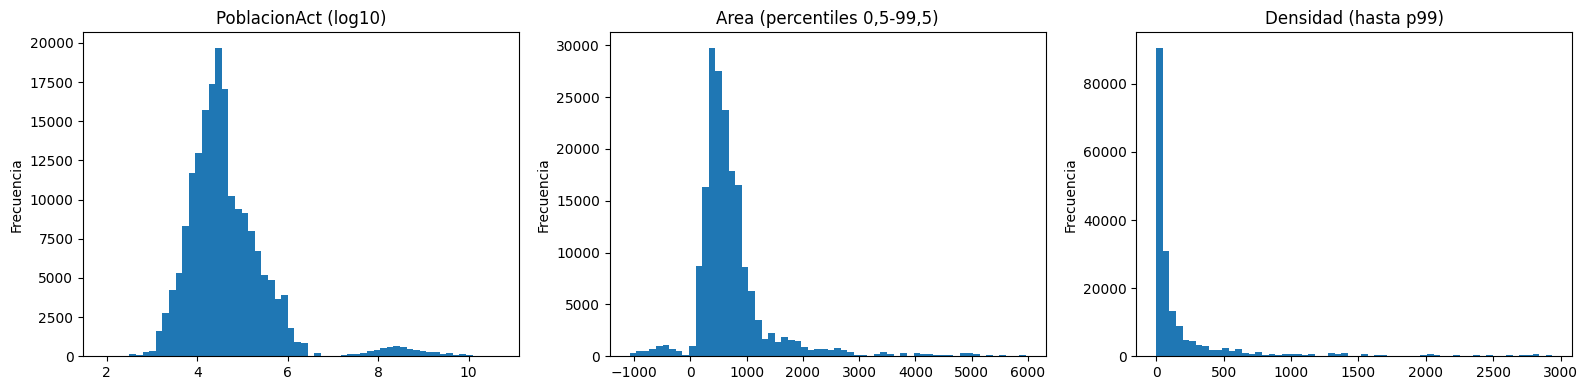

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pd_a = pandas_fuentes['FuenteAreasDeServicio']
axes[0].hist(np.log10(pd_a['PoblacionAct'].dropna().clip(lower=1)), bins=60)
axes[0].set_title('PoblacionAct (log10)')
axes[1].hist(pd_a['Area'].dropna(), bins=60, range=(pd_a['Area'].quantile(0.005), pd_a['Area'].quantile(0.995)))
axes[1].set_title('Area (percentiles 0,5-99,5)')
axes[2].hist(pd_a['Densidad'].dropna(), bins=60, range=(0, pd_a['Densidad'].quantile(0.99)))
axes[2].set_title('Densidad (hasta p99)')
for ax in axes:
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

##### 3.4 Variables categóricas y temporales

In [37]:
frecuencias(areas_de_servicio, 'Fecha')

,Fecha,count,%
0,2017,99211,52.54
1,2018,83322,44.13
2,1800,6282,3.33


In [38]:
frecuencias(areas_de_servicio, 'Estado', 40)

,Estado,count,%
0,Indiana,14150,7.49
1,Missouri,13913,7.37
2,Georgia,13822,7.32
3,Wisconsin,12543,6.64
4,Michigan,11598,6.14
5,Texas,11261,5.96
6,South Dakota,10930,5.79
7,Kansas,10824,5.73
8,Kentucky,10571,5.60
9,Oklahoma,8183,4.33


In [39]:
# Sufijo del nombre del condado (County, Parish, Borough, ...)
sufijo = areas_de_servicio.withColumn('sufijo_condado', f.regexp_extract('Condado', r'(\S+)$', 1))
frecuencias(sufijo, 'sufijo_condado')

,sufijo_condado,count,%
0,County,185460,98.22
1,City,2690,1.42
2,Parish,337,0.18
3,Borough,205,0.11
4,Wrangell,25,0.01
5,Juneau,23,0.01
6,Yakutat,20,0.01
7,Skagway,19,0.01
8,Anchorage,18,0.01
9,Sitka,13,0.01


In [40]:
# Estados en los que aparecen los condados que no terminan en "County"
(sufijo.filter(col('sufijo_condado') != 'County')
       .groupBy('sufijo_condado').agg(f.count('*').alias('filas'),
                                      f.array_sort(f.collect_set('Estado')).alias('estados'))
       .orderBy(f.desc('filas')).toPandas())

,sufijo_condado,filas,estados
0,City,2690,"[Missouri, Virginia]"
1,Parish,337,[Louisiana]
2,Borough,205,[Alaska]
3,Wrangell,25,[Alaska]
4,Juneau,23,[Alaska]
5,Yakutat,20,[Alaska]
6,Skagway,19,[Alaska]
7,Anchorage,18,[Alaska]
8,Sitka,13,[Alaska]
9,Bedford,5,[Virginia]


##### 3.5 Formatos de identificadores y textos

In [41]:
# Estados asociados a cada longitud de IdGeografia_T
(areas_de_servicio.withColumn('digitos', f.length(col('IdGeografia_T').cast('string')))
    .groupBy('digitos').agg(f.count('*').alias('filas'), f.countDistinct('Estado').alias('estados_distintos'),
                            f.slice(f.array_sort(f.collect_set('Estado')), 1, 8).alias('primeros_estados'))
    .orderBy('digitos').toPandas())

,digitos,filas,estados_distintos,primeros_estados
0,NaN,6378,35,"[Alabama, Alaska, Arizona, Arkansas, Delaware, Florida, ..."
1,4.00,2024,4,"[Alabama, Alaska, Arizona, Arkansas]"
2,5.00,166700,33,"[Arizona, Arkansas, Delaware, Florida, Georgia, Hawaii, ..."
3,6.00,13713,16,"[New Jersey, New Mexico, North Carolina, North Dakota, O..."


In [42]:
# Descomposición de NombreAreaDeServicio: texto + código con formato de IdPlan_T + 4 dígitos + consecutivo
regex_nombre = r'^(.*?)(\d{5}[A-Z]{2}\d{7}-\d{2})(\d{4})(\d+)$'
areas_de_servicio.select(
    f.count('*').alias('filas'),
    f.sum(col('NombreAreaDeServicio').rlike(regex_nombre).cast('int')).alias('cumplen_estructura')).show()

nombres = areas_de_servicio.select('NombreAreaDeServicio', 'Fecha',
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 1).alias('texto'),
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 2).alias('codigo_plan'),
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 3).alias('anio_en_nombre'),
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 4).alias('consecutivo'))
nombres.show(5, truncate=False)
frecuencias(nombres, 'anio_en_nombre')

+------+------------------+
| filas|cumplen_estructura|
+------+------------------+
|188815|            188815|
+------+------------------+

+---------------------------------------------+-----+--------------------+-----------------+--------------+-----------+
|NombreAreaDeServicio                         |Fecha|texto               |codigo_plan      |anio_en_nombre|consecutivo|
+---------------------------------------------+-----+--------------------+-----------------+--------------+-----------+
|New Jersey - Medical91661NJ2340003-0520174859|2017 |New Jersey - Medical|91661NJ2340003-05|2017          |4859       |
|New Jersey - Medical91661NJ2340003-0520184611|2018 |New Jersey - Medical|91661NJ2340003-05|2018          |4611       |
|BlueOptions16842FL0070128-032017260          |2017 |BlueOptions         |16842FL0070128-03|2017          |260        |
|New Jersey - Medical91661NJ2340003-0520184591|2018 |New Jersey - Medical|91661NJ2340003-05|2018          |4591       |
|New Jersey - Medic

,anio_en_nombre,count,%
0,2017,102681,54.38
1,2018,86134,45.62


In [43]:
# Granularidad: cuántas filas hay por área de servicio y cuántos condados cubre cada una
gran = (areas_de_servicio.filter(col('IdAreaDeServicio_T').isNotNull())
        .groupBy('IdAreaDeServicio_T')
        .agg(f.count('*').alias('filas'), f.countDistinct('Condado', 'Estado').alias('condados'),
             f.countDistinct('Estado').alias('estados')))
gran.select([f.percentile_approx(c, [0.0, 0.25, 0.5, 0.75, 1.0], 10000).alias(c) for c in ['filas', 'condados', 'estados']]).toPandas().T \
    .rename(columns={0: '[min, p25, mediana, p75, max]'})

,"[min, p25, mediana, p75, max]"
filas,"[1, 11, 22, 46, 237]"
condados,"[1, 7, 14, 29, 154]"
estados,"[1, 1, 1, 1, 1]"


**Observaciones del perfilamiento – FuenteAreasDeServicio**

- **Contenido de una fila:** un condado (`Condado`, `Estado`, `IdGeografia_T`) asociado a un área de servicio (`IdAreaDeServicio_T`, `NombreAreaDeServicio`) y a un año (`Fecha`), con `PoblacionAct`, `Area` y `Densidad`.
- **Cardinalidad:** 5.409 `IdAreaDeServicio_T` distintos, 1.398 nombres de condado, 35 estados y 3 valores de `Fecha`. Cada área de servicio aparece en un solo estado (`estados` máx = 1) y cubre entre 1 y 154 condados (mediana 14). Tiene entre 1 y 237 filas (mediana 22).
- **Completitud:**
  - `IdAreaDeServicio_T`: 6.288 nulos (3,33%).
  - `IdGeografia_T`: 6.378 nulos (3,38%).
  - `Area` y `Densidad`: 2.407 nulos cada una (1,27%).
  - Las columnas de texto no tienen nulos ni cadenas vacías.
- **Variables numéricas:**
  - `PoblacionAct` va de 82 a 4,73·10¹⁰. La mediana es 30.885, el p75 110.686 y el p99 6,69·10⁸; la media (41.479.590) está muy por encima de la mediana. Asimetría 32,63 y curtosis 1.632,83.
  - `Area` va de -24.707 a 88.824, con mediana 575. Hay **6.177 valores negativos** y el p01 es -805.
  - `Densidad` va de 0 a 14.946, con mediana 51, 769 ceros y ningún valor negativo.
- **Variables categóricas:**
  - `Fecha`: 2017 (52,54%), 2018 (44,13%) y **1800 (6.282 filas; 3,33%)**.
  - `Estado`: los más frecuentes son Indiana (7,49%), Missouri (7,37%) y Georgia (7,32%); los menos frecuentes, Hawaii y Delaware (0,02%).
  - `Condado`: el 98,22% termina en *County*. Los otros sufijos son *City* (Missouri y Virginia), *Parish* (Louisiana), *Borough* (Alaska), *Bedford* (Virginia) y nombres de Alaska sin sufijo (Wrangell, Juneau, Yakutat, Skagway, Anchorage, Sitka).
- **Formatos:**
  - `IdAreaDeServicio_T` tiene de 5 a 9 dígitos. Sus últimos 4 dígitos son siempre 2017 (52,56%) o 2018 (44,11%); el resto son nulos.
  - `IdGeografia_T` tiene 4 dígitos (1,07%, solo en Alabama, Alaska, Arizona y Arkansas), 5 dígitos (88,29%, en 33 estados) o 6 dígitos (7,26%, en 16 estados).
  - `NombreAreaDeServicio` (27 a 80 caracteres) cumple en las 188.815 filas la estructura *texto + código con el formato de `IdPlan_T` (`99999AA9999999-99`) + 4 dígitos + consecutivo*. Ejemplo: `BlueOptions` + `16842FL0070128-03` + `2017` + `260`. Los 4 dígitos son 2017 (54,38%) o 2018 (45,62%).

#### 4. FuenteCondicionesDePago
##### 4.1 Estructura y contenido completo
Al ser un catálogo pequeño se muestra completo.

In [44]:
condiciones_de_pago.printSchema()
condiciones_de_pago.orderBy('IdCondicionesDePago_T').show(50, truncate=False)

root
 |-- IdCondicionesDePago_T: integer (nullable = true)
 |-- Descripcion: string (nullable = true)
 |-- Tipo: string (nullable = true)

+---------------------+--------------------------------+-------------+
|IdCondicionesDePago_T|Descripcion                     |Tipo         |
+---------------------+--------------------------------+-------------+
|9                    |No Charge                       |Coseguridad  |
|17                   |Copay per Day after deductible  |Copago       |
|18                   |No Charge after deductible      |Coseguro     |
|27                   |Coinsurance after deductible    |Coseguro     |
|27                   |Coinsurance after deductible    |Coseguro     |
|34                   |Not Applicable                  |Copagado     |
|36                   |Not Applicable                  |Coseguro     |
|45                   |Coinsurance                     |Coseguro     |
|45                   |Coinsurance                     |Coseguro     |
|51      

##### 4.2 Perfil por columna

In [45]:
perfil_columnas(condiciones_de_pago)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdCondicionesDePago_T,int,31,0,0.00,0,23,74.19,9,714,1,3
Descripcion,string,31,0,0.00,0,17,54.84,Coinsurance,Not Applicable,5,32
Tipo,string,31,0,0.00,0,6,19.35,Copagado,SinTipoCopago,3,13


##### 4.3 Distribución de valores

In [46]:
frecuencias(condiciones_de_pago, 'Tipo')

,Tipo,count,%
0,Copago,19,61.29
1,Coseguro,7,22.58
2,NaN,2,6.45
3,Copagado,1,3.23
4,Coseguridad,1,3.23
5,SinTipoCopago,1,3.23


In [47]:
frecuencias(condiciones_de_pago, 'Descripcion', 20)

,Descripcion,count,%
0,Coinsurance,3,9.68
1,Copay per Stay,3,9.68
2,Copay per Stay after deductible,3,9.68
3,No Charge,3,9.68
4,No Charge after deductible,3,9.68
5,Coinsurance after deductible,2,6.45
6,Copay,2,6.45
7,Copay per Day with deductible,2,6.45
8,Not Applicable,2,6.45
9,Copay after deductible,1,3.23


In [48]:
# Componentes de la descripción: tipo de cargo y relación con el deducible
comp = (condiciones_de_pago
        .withColumn('cargo', f.regexp_extract('Descripcion', r'^(Copay per Day|Copay per Stay|Copay|Coinsurance|No Charge|Not Applicable)', 1))
        .withColumn('deducible', f.regexp_extract('Descripcion', r'(after|before|with) deductible$', 1)))
comp.groupBy('cargo', 'deducible').count().orderBy('cargo', 'deducible').toPandas()

,cargo,deducible,count
0,Coinsurance,,3
1,Coinsurance,after,2
2,Copay,,2
3,Copay,after,1
4,Copay,before,1
5,Copay,with,1
6,Copay per Day,,1
7,Copay per Day,after,1
8,Copay per Day,before,1
9,Copay per Day,with,2


**Observaciones del perfilamiento – FuenteCondicionesDePago**

- **Contenido de una fila:** una condición de pago (`IdCondicionesDePago_T`) con su `Descripcion` y su `Tipo`.
- **Cardinalidad:** 31 filas con **23 Id distintos** (entre 9 y 714), 17 descripciones y 6 tipos.
- **Completitud:** no hay nulos ni cadenas vacías, pero `Tipo` contiene **2 veces el texto `NaN`**.
- **Distribución de `Tipo`:** `Copago` (61,29%), `Coseguro` (22,58%), `NaN` (6,45%), y `Copagado`, `Coseguridad` y `SinTipoCopago` (3,23% cada uno).
- **Formato de `Descripcion`:** todas las descripciones se componen de un tipo de cargo (*Copay*, *Copay per Day*, *Copay per Stay*, *Coinsurance*, *No Charge* o *Not Applicable*), seguido o no de una relación con el deducible (*after*, *before* o *with deductible*).

#### 5. FuentePlanesBeneficio
##### 5.1 Estructura y muestra

In [49]:
planes_beneficio.printSchema()
planes_beneficio.show(5, truncate=False)

root
 |-- IdTipoBeneficio_T: long (nullable = true)
 |-- IdAreaDeServicio_T: long (nullable = true)
 |-- IdCondicionDePagoCopago_T: integer (nullable = true)
 |-- IdCondicionDePagoCoseguro_T: integer (nullable = true)
 |-- IdNivelServicio_T: integer (nullable = true)
 |-- IdPlan_T: string (nullable = true)
 |-- Fecha: string (nullable = true)
 |-- IdProveedor_T: integer (nullable = true)
 |-- valorCopago: integer (nullable = true)
 |-- valorCoseguro: integer (nullable = true)
 |-- cantidadLimite: integer (nullable = true)

+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|IdPlan_T         |Fecha     |IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+-----------------

##### 5.2 Perfil por columna

In [50]:
perfil_columnas(planes_beneficio)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdTipoBeneficio_T,bigint,33950,2086,5.79,0,285,0.79,5,2110,1,4
IdAreaDeServicio_T,bigint,33995,2041,5.66,0,6496,18.03,12018,235734036,5,9
IdCondicionDePagoCopago_T,int,36036,0,0.00,0,14,0.04,17,238,2,3
IdCondicionDePagoCoseguro_T,int,36036,0,0.00,0,5,0.01,9,45,1,2
IdNivelServicio_T,int,36036,0,0.00,0,3,0.01,1,3,1,1
IdPlan_T,string,36036,0,0.00,2053,393,1.09,,99969OH0080069-00,0,17
Fecha,string,36036,0,0.00,0,5,0.01,1920-12-31,"Dec 31,2018",10,11
IdProveedor_T,int,36036,0,0.00,0,125,0.35,10207,99969,5,5
valorCopago,int,36036,0,0.00,0,49,0.14,0,3500,1,4


##### 5.3 Estadísticos de las variables numéricas

In [51]:
estadisticos_numericos(planes_beneficio, ['valorCopago', 'valorCoseguro', 'cantidadLimite'])

,n,media,desv_est,min,p01,p25,mediana,p75,p99,max,asimetria,curtosis,ceros,negativos
columna,,,,,,,,,,,,,,
valorCopago,36036,9.78,100.41,0,0,0,0,0,250,3500,19.87,522.89,34060,0
valorCoseguro,36036,24.29,36.96,0,0,0,0,50,100,100,1.26,-0.00,21962,0
cantidadLimite,5465,129.33,951.28,1,1,1,25,40,2500,30000,20.60,565.67,0,0


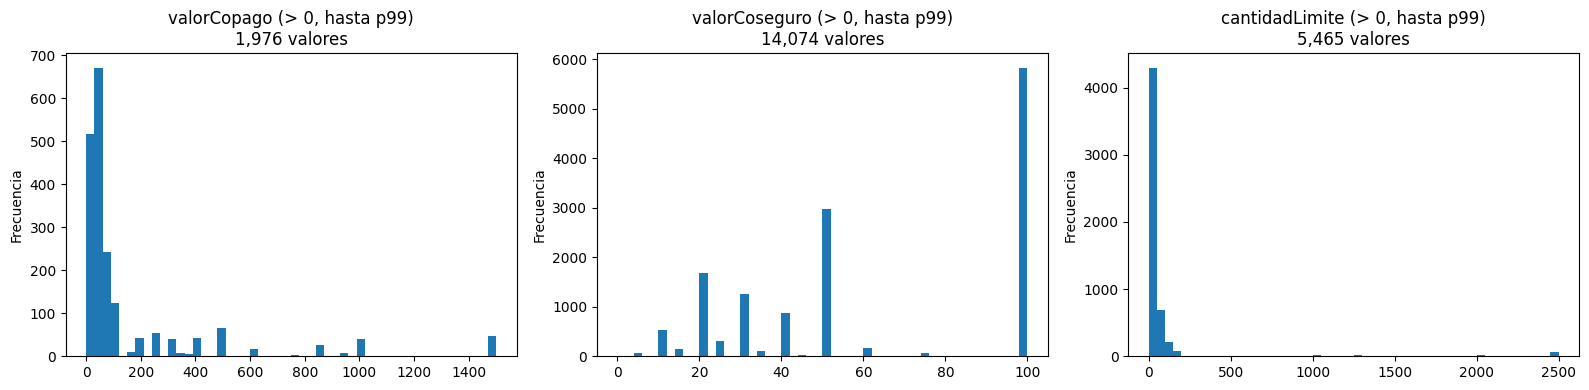

In [52]:
pd_p = pandas_fuentes['FuentePlanesBeneficio']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['valorCopago', 'valorCoseguro', 'cantidadLimite']):
    s = pd_p[c].dropna()
    s = s[s > 0]
    ax.hist(s, bins=50, range=(0, s.quantile(0.99)) if len(s) else None)
    ax.set_title(f'{c} (> 0, hasta p99)\n{len(s):,} valores')
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

In [53]:
# Valores más frecuentes de las medidas (muestran si son valores "redondos" o continuos)
for c in ['valorCopago', 'valorCoseguro', 'cantidadLimite']:
    print(c)
    display(frecuencias(planes_beneficio, c, 10))

valorCopago


,valorCopago,count,%
0,0,34060,94.52
1,50,250,0.69
2,30,160,0.44
3,20,136,0.38
4,10,115,0.32
5,35,114,0.32
6,100,91,0.25
7,40,88,0.24
8,15,87,0.24
9,60,78,0.22


valorCoseguro


,valorCoseguro,count,%
0,0,21962,60.94
1,100,5836,16.19
2,50,2976,8.26
3,20,1679,4.66
4,30,1267,3.52
5,40,883,2.45
6,10,526,1.46
7,25,316,0.88
8,60,166,0.46
9,15,149,0.41


cantidadLimite


,cantidadLimite,count,%
0,NaN,30571,84.83
1,1.00,1725,4.79
2,30.00,637,1.77
3,60.00,580,1.61
4,35.00,418,1.16
5,20.00,366,1.02
6,2.00,290,0.80
7,25.00,216,0.60
8,40.00,175,0.49
9,100.00,150,0.42


##### 5.4 Variables categóricas y llaves foráneas

In [54]:
frecuencias(planes_beneficio, 'IdNivelServicio_T')

,IdNivelServicio_T,count,%
0,1,12045,33.42
1,3,12028,33.38
2,2,11963,33.20


In [55]:
frecuencias(planes_beneficio, 'IdCondicionDePagoCopago_T')

,IdCondicionDePagoCopago_T,count,%
0,238,18123,50.29
1,34,16364,45.41
2,51,612,1.70
3,207,325,0.90
4,153,290,0.80
5,170,124,0.34
6,102,50,0.14
7,187,49,0.14
8,68,31,0.09
9,136,25,0.07


In [56]:
frecuencias(planes_beneficio, 'IdCondicionDePagoCoseguro_T')

,IdCondicionDePagoCoseguro_T,count,%
0,45,22762,63.16
1,27,8354,23.18
2,36,3785,10.50
3,18,664,1.84
4,9,471,1.31


In [57]:
frecuencias(planes_beneficio, 'IdProveedor_T', 10)

,IdProveedor_T,count,%
0,33602,3759,10.43
1,67243,1657,4.60
2,41921,1581,4.39
3,36096,1395,3.87
4,40047,1308,3.63
5,37833,1292,3.59
6,87571,1048,2.91
7,28162,1042,2.89
8,66252,931,2.58
9,38166,921,2.56


##### 5.5 Formatos: `Fecha` (texto) e `IdPlan_T`

In [58]:
frecuencias(planes_beneficio, 'Fecha')

,Fecha,count,%
0,2017-12-31,16134,44.77
1,2018-12-31,15794,43.83
2,1920-12-31,2052,5.69
3,"Dec 31,2017",1029,2.86
4,"Dec 31,2018",1027,2.85


In [59]:
# Filas con cada valor de Fecha según si IdPlan_T está vacío
(planes_beneficio.groupBy('Fecha', (f.trim(col('IdPlan_T')) == '').alias('IdPlan_T_vacio'))
    .count().orderBy('Fecha', 'IdPlan_T_vacio').toPandas())

,Fecha,IdPlan_T_vacio,count
0,1920-12-31,False,2052
1,2017-12-31,False,15106
2,2017-12-31,True,1028
3,2018-12-31,False,14769
4,2018-12-31,True,1025
5,"Dec 31,2017",False,1029
6,"Dec 31,2018",False,1027


In [60]:
# Componentes de IdPlan_T: primeros 5 dígitos frente a IdProveedor_T, y las 2 letras
planes_no_vacios = planes_beneficio.filter(f.trim(col('IdPlan_T')) != '')
planes_no_vacios.select(
    f.count('*').alias('filas_IdPlan_no_vacio'),
    f.sum((f.substring('IdPlan_T', 1, 5) == col('IdProveedor_T').cast('string')).cast('int')).alias('prefijo_igual_a_IdProveedor_T')).show()
frecuencias(planes_no_vacios.withColumn('letras_IdPlan_T', f.substring('IdPlan_T', 6, 2)), 'letras_IdPlan_T', 40)

+---------------------+-----------------------------+
|filas_IdPlan_no_vacio|prefijo_igual_a_IdProveedor_T|
+---------------------+-----------------------------+
|                33983|                        33983|
+---------------------+-----------------------------+



,letras_IdPlan_T,count,%
0,TX,5215,15.35
1,WI,3279,9.65
2,MI,2753,8.10
3,IL,2247,6.61
4,LA,1893,5.57
5,GA,1855,5.46
6,VA,1838,5.41
7,OH,1535,4.52
8,FL,1460,4.30
9,NJ,1138,3.35


In [61]:
# Granularidad: filas (beneficios) por plan y planes por proveedor
por_plan = planes_beneficio.filter(f.trim(col('IdPlan_T')) != '').groupBy('IdPlan_T').count()
por_prov = planes_beneficio.groupBy('IdProveedor_T').agg(f.countDistinct('IdPlan_T').alias('planes'))
print('Planes distintos:', por_plan.count(), '| Proveedores distintos:', por_prov.count())
pd.DataFrame({
    'beneficios_por_plan': por_plan.select(f.percentile_approx('count', [0.0, 0.25, 0.5, 0.75, 1.0], 10000)).first()[0],
    'planes_por_proveedor': por_prov.select(f.percentile_approx('planes', [0.0, 0.25, 0.5, 0.75, 1.0], 10000)).first()[0],
}, index=['min', 'p25', 'mediana', 'p75', 'max'])

Planes distintos: 392 | Proveedores distintos: 125


,beneficios_por_plan,planes_por_proveedor
min,1,1
p25,7,2
mediana,13,2
p75,218,4
max,1240,38


**Observaciones del perfilamiento – FuentePlanesBeneficio**

- **Contenido de una fila:** un tipo de beneficio (`IdTipoBeneficio_T`) dentro de un plan (`IdPlan_T`) de un proveedor (`IdProveedor_T`), en un área de servicio (`IdAreaDeServicio_T`), un nivel de servicio (`IdNivelServicio_T`) y una `Fecha`. Incluye sus condiciones de pago (`IdCondicionDePagoCopago_T`, `IdCondicionDePagoCoseguro_T`) y los valores `valorCopago`, `valorCoseguro` y `cantidadLimite`.
- **Cardinalidad:** 392 planes, 125 proveedores, 285 tipos de beneficio, 6.496 áreas de servicio y 3 niveles de servicio (33,42%, 33,38% y 33,20% de las filas).
  - Cada plan tiene entre 1 y 1.240 filas (mediana 13, p75 218).
  - Cada proveedor tiene entre 1 y 38 planes (mediana 2).
  - El proveedor 33602 tiene el 10,43% de las filas.
- **Completitud:**
  - `IdTipoBeneficio_T`: 2.086 nulos (5,79%).
  - `IdAreaDeServicio_T`: 2.041 nulos (5,66%).
  - `IdPlan_T`: ningún nulo, pero **2.053 cadenas vacías (5,70%)**.
  - `cantidadLimite`: **30.571 nulos (84,83%)**.
- **Variables numéricas:**
  - `valorCopago` va de 0 a 3.500. Es 0 en el **94,52%** de las filas (mediana y p75 = 0, p99 = 250), con asimetría 19,87. Los valores distintos de 0 más frecuentes son 50, 30, 20, 10 y 35.
  - `valorCoseguro` va de 0 a 100 y es 0 en el 60,94% de las filas. Los valores distintos de 0 más frecuentes son 100 (16,19%), 50 (8,26%) y 20 (4,66%).
  - `cantidadLimite` va de 1 a 30.000, con mediana 25, p99 2.500 y asimetría 20,60.
- **Llaves hacia los catálogos:**
  - `IdCondicionDePagoCopago_T` toma 14 valores: el 238 (*Copay* en el catálogo) tiene el 50,29% de las filas y el 34 (*Not Applicable*) el 45,41%.
  - `IdCondicionDePagoCoseguro_T` toma 5 valores: el 45 (*Coinsurance*) tiene el 63,16%.
- **Formatos:**
  - `Fecha` es texto con 5 valores y dos formatos: `yyyy-MM-dd` (94,29%) y `MMM dd,yyyy` (5,71%). Los valores son `2017-12-31` (44,77%), `2018-12-31` (43,83%), **`1920-12-31` (5,69%)**, `Dec 31,2017` (2,86%) y `Dec 31,2018` (2,85%).
  - Los 2.053 `IdPlan_T` vacíos están en las fechas `2017-12-31` (1.028) y `2018-12-31` (1.025). Ninguno coincide con las fechas `1920-12-31` ni con el formato `MMM dd,yyyy`.
  - Todos los `IdPlan_T` no vacíos tienen el formato `99999AA9999999-99` (17 caracteres). En las 33.983 filas, los 5 primeros dígitos son iguales a `IdProveedor_T`. Las 2 letras toman 35 valores (TX 15,35%, WI 9,65%, MI 8,10%...).
  - `IdAreaDeServicio_T` tiene de 5 a 9 dígitos, igual que en FuenteAreasDeServicio.

#### 6. FuenteTiposBeneficio
##### 6.1 Estructura y muestra

In [62]:
tipos_beneficio.printSchema()
tipos_beneficio.show(5, truncate=False)

root
 |-- IdTipoBeneficio_T: integer (nullable = true)
 |-- Nombre: string (nullable = true)
 |-- UnidadDelLimite: string (nullable = true)
 |-- EsEHB: string (nullable = true)
 |-- EstaCubiertaPorSeguro: string (nullable = true)
 |-- TieneLimiteCuantitativo: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoDentroDeLaRed: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoFueraDeLaRed: string (nullable = true)
 |-- Fecha: integer (nullable = true)

+-----------------+-----------------------------+------------------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|Nombre                       |UnidadDelLimite         |EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+-----------------------------+------------------------+-----+---------------------+---

##### 6.2 Perfil por columna

In [63]:
perfil_columnas(tipos_beneficio)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdTipoBeneficio_T,int,849,0,0.00,0,178,20.97,5,1055,1,4
Nombre,string,849,0,0.00,0,178,20.97,Abortion for Which Public Funding is Prohibited,X-rays and Diagnostic Imaging,4,63
UnidadDelLimite,string,849,0,0.00,559,63,7.42,,Visit(s) per year,0,93
EsEHB,string,849,0,0.00,0,3,0.35,No,Yes,2,4
EstaCubiertaPorSeguro,string,849,0,0.00,0,3,0.35,False,Yes,2,5
TieneLimiteCuantitativo,string,849,0,0.00,0,4,0.47,Nein,Yes,2,4
ExcluidoDelDesembolsoMaximoDentroDeLaRed,string,849,0,0.00,0,3,0.35,Algunas veces,Yes,2,13
ExcluidoDelDesembolsoMaximoFueraDeLaRed,string,849,0,0.00,0,2,0.24,No,Yes,2,3
Fecha,int,849,0,0.00,0,2,0.24,2017,2018,4,4


##### 6.3 Variables categóricas (banderas)
Las columnas `Es...`, `Esta...`, `Tiene...` y `Excluido...` son banderas; se revisa qué valores toman y con qué frecuencia.

In [64]:
banderas = ['EsEHB', 'EstaCubiertaPorSeguro', 'TieneLimiteCuantitativo',
            'ExcluidoDelDesembolsoMaximoDentroDeLaRed', 'ExcluidoDelDesembolsoMaximoFueraDeLaRed']
total_tipos = tipos_beneficio.count()
tabla_banderas = {}
for c in banderas:
    vc = tipos_beneficio.groupBy(c).count().toPandas()
    vc[c] = vc[c].fillna('<NULL>')
    tabla_banderas[c] = vc.set_index(c)['count']
pd.DataFrame(tabla_banderas).fillna(0).astype(int)

,EsEHB,EstaCubiertaPorSeguro,TieneLimiteCuantitativo,ExcluidoDelDesembolsoMaximoDentroDeLaRed,ExcluidoDelDesembolsoMaximoFueraDeLaRed
Algunas veces,0,0,0,2,0
False,0,8,0,0,0
Nein,0,0,24,0,0
No,399,98,542,787,516
Si,0,0,12,0,0
True,20,0,0,0,0
Yes,430,743,271,60,333


In [65]:
frecuencias(tipos_beneficio, 'Fecha')

,Fecha,count,%
0,2017,672,79.15
1,2018,177,20.85


In [66]:
# Filas frente a identificadores distintos
tipos_beneficio.select(f.count('*').alias('filas'),
                            f.countDistinct('IdTipoBeneficio_T').alias('IdTipoBeneficio_T_distintos'),
                            f.countDistinct('IdTipoBeneficio_T', 'Fecha').alias('combinaciones_Id_Fecha')).show()

+-----+---------------------------+----------------------+
|filas|IdTipoBeneficio_T_distintos|combinaciones_Id_Fecha|
+-----+---------------------------+----------------------+
|  849|                        178|                   218|
+-----+---------------------------+----------------------+



In [67]:
frecuencias(tipos_beneficio, 'UnidadDelLimite', 25)

,UnidadDelLimite,count,%
0,,559,65.84
1,Visit(s) per Year,64,7.54
2,Visit(s) per Benefit Period,31,3.65
3,Days per Year,14,1.65
4,Days per Benefit Period,13,1.53
5,Visit(s) per YearVisit(s) per YearVisit(s) per Year,11,1.30
6,Exam(s) per Year,10,1.18
7,Item(s) per Year,10,1.18
8,Dollars per Year,9,1.06
9,Visit(s) per 6 Months,7,0.82


In [68]:
# UnidadDelLimite vacía según TieneLimiteCuantitativo
(tipos_beneficio.groupBy('TieneLimiteCuantitativo')
    .agg(f.count('*').alias('filas'),
         f.sum((f.trim(col('UnidadDelLimite')) == '').cast('int')).alias('UnidadDelLimite_vacia'))
    .orderBy(f.desc('filas')).toPandas())

,TieneLimiteCuantitativo,filas,UnidadDelLimite_vacia
0,No,542,522
1,Yes,271,13
2,Nein,24,24
3,Si,12,0


In [69]:
# Longitud de los nombres de beneficio
tipos_beneficio.select(f.length('Nombre').alias('long_nombre')).summary('count', 'min', '25%', '50%', '75%', 'max').show()
frecuencias(tipos_beneficio, 'Nombre', 10)

+-------+-----------+
|summary|long_nombre|
+-------+-----------+
|  count|        849|
|    min|          4|
|    25%|         18|
|    50%|         24|
|    75%|         29|
|    max|         63|
+-------+-----------+



,Nombre,count,%
0,Dental Check-Up for Children,29,3.42
1,Skilled Nursing Facility,26,3.06
2,Orthodontia - Child,21,2.47
3,Routine Eye Exam (Adult),20,2.36
4,Hearing Aids,19,2.24
5,Private-Duty Nursing,19,2.24
6,Routine Eye Exam for Children,19,2.24
7,Eye Glasses for Children,18,2.12
8,Chiropractic Care,17,2.00
9,Nutritional Counseling,17,2.00


**Observaciones del perfilamiento – FuenteTiposBeneficio**

- **Contenido de una fila:** un tipo de beneficio (`IdTipoBeneficio_T`, `Nombre`) en un año (`Fecha`), con la unidad de su límite y cinco banderas.
- **Cardinalidad:** **849 filas, 178 Id distintos (y 178 nombres) y 218 combinaciones de Id + `Fecha`**. `Fecha` es 2017 en el 79,15% de las filas y 2018 en el 20,85%.
- **Completitud:** no hay nulos. `UnidadDelLimite` está **vacía en 559 filas (65,84%)**. Según `TieneLimiteCuantitativo`, está vacía en:
  - 522 de 542 filas con `No`;
  - 24 de 24 con `Nein`;
  - 13 de 271 con `Yes`;
  - 0 de 12 con `Si`.
- **Banderas (texto):**
  - `EsEHB`: Yes (430), No (399), True (20).
  - `EstaCubiertaPorSeguro`: Yes (743), No (98), False (8).
  - `TieneLimiteCuantitativo`: No (542), Yes (271), Nein (24), Si (12).
  - `ExcluidoDelDesembolsoMaximoDentroDeLaRed`: No (787), Yes (60), Algunas veces (2).
  - `ExcluidoDelDesembolsoMaximoFueraDeLaRed`: No (516), Yes (333).
- **Formato de `UnidadDelLimite`:** tiene 63 valores distintos, de la forma `<unidad> per <periodo>` (p. ej. *Visit(s) per Year*, *Days per Benefit Period*). Aparecen variaciones de mayúsculas (*Visit(s) per Year* y *Visit(s) per year*) y valores repetidos varias veces dentro del mismo texto (*Visit(s) per YearVisit(s) per YearVisit(s) per Year*). La longitud llega a 93 caracteres.
- **Otros formatos:** `IdTipoBeneficio_T` tiene de 1 a 4 dígitos (de 5 a 1.055; el 82,57% tiene 3 dígitos). `Nombre` tiene de 4 a 63 caracteres (mediana 24).

#### 7. Relaciones entre las fuentes
Se identifican las columnas que conectan las tablas y el rango de años que cubre cada una (el detalle de integridad referencial se evalúa en calidad de datos).

In [70]:
relaciones = pd.DataFrame([
    ('FuentePlanesBeneficio.IdAreaDeServicio_T', 'FuenteAreasDeServicio.IdAreaDeServicio_T'),
    ('FuentePlanesBeneficio.IdTipoBeneficio_T', 'FuenteTiposBeneficio.IdTipoBeneficio_T'),
    ('FuentePlanesBeneficio.IdCondicionDePagoCopago_T', 'FuenteCondicionesDePago.IdCondicionesDePago_T'),
    ('FuentePlanesBeneficio.IdCondicionDePagoCoseguro_T', 'FuenteCondicionesDePago.IdCondicionesDePago_T'),
], columns=['columna_origen', 'columna_destino'])

def perfil_llave(ref):
    tabla, c = ref.split('.')
    r = fuentes[tabla].agg(f.countDistinct(c), f.min(c), f.max(c)).first()
    return pd.Series({'distintos': r[0], 'min': r[1], 'max': r[2]})

pd.concat([relaciones,
           relaciones['columna_origen'].apply(perfil_llave).add_suffix('_origen'),
           relaciones['columna_destino'].apply(perfil_llave).add_suffix('_destino')], axis=1)

,columna_origen,columna_destino,distintos_origen,min_origen,max_origen,distintos_destino,min_destino,max_destino
0,FuentePlanesBeneficio.IdAreaDeServicio_T,FuenteAreasDeServicio.IdAreaDeServicio_T,6496,12018,235734036,5409,12018,117872018
1,FuentePlanesBeneficio.IdTipoBeneficio_T,FuenteTiposBeneficio.IdTipoBeneficio_T,285,5,2110,178,5,1055
2,FuentePlanesBeneficio.IdCondicionDePagoCopago_T,FuenteCondicionesDePago.IdCondicionesDePago_T,14,17,238,23,9,714
3,FuentePlanesBeneficio.IdCondicionDePagoCoseguro_T,FuenteCondicionesDePago.IdCondicionesDePago_T,5,9,45,23,9,714


In [71]:
anios = pd.DataFrame({
    'FuenteAreasDeServicio': areas_de_servicio.groupBy('Fecha').count().toPandas().set_index('Fecha')['count'],
    'FuenteTiposBeneficio': tipos_beneficio.groupBy('Fecha').count().toPandas().set_index('Fecha')['count'],
    'FuentePlanesBeneficio (año del texto)': planes_beneficio
        .groupBy(f.regexp_extract('Fecha', r'(\d{4})', 1).cast('int').alias('Fecha')).count()
        .toPandas().set_index('Fecha')['count'],
}).fillna(0).astype(int).sort_index()
anios

,FuenteAreasDeServicio,FuenteTiposBeneficio,FuentePlanesBeneficio (año del texto)
Fecha,,,
1800,6282,0,0
1920,0,0,2052
2017,99211,672,17163
2018,83322,177,16821


**Columnas que conectan las fuentes:**
- `IdAreaDeServicio_T` toma 6.496 valores en FuentePlanesBeneficio (máximo 235.734.036) y 5.409 en FuenteAreasDeServicio (máximo 117.872.018).
- `IdTipoBeneficio_T` toma 285 valores en FuentePlanesBeneficio (máximo 2.110) y 178 en FuenteTiposBeneficio (máximo 1.055).
- Las condiciones de copago (14 valores, de 17 a 238) y de coseguro (5 valores, de 9 a 45) de FuentePlanesBeneficio están dentro del rango del catálogo (23 valores, de 9 a 714).

**Cobertura temporal:** las tres tablas con año tienen 2017 y 2018. Además, FuenteAreasDeServicio tiene 6.282 filas con 1800 y FuentePlanesBeneficio 2.052 filas con 1920. FuenteCondicionesDePago no tiene columna de fecha.

#### 8. Resumen del perfilamiento

| Tabla | Filas | Columnas | % de filas | Una fila contiene |
|---|---:|---:|---:|---|
| FuenteAreasDeServicio | 188.815 | 9 | 83,65 | condado + área de servicio + año, con población, área y densidad |
| FuenteCondicionesDePago | 31 | 3 | 0,01 | condición de pago con descripción y tipo |
| FuentePlanesBeneficio | 36.036 | 11 | 15,96 | tipo de beneficio + plan + área + nivel + fecha, con condiciones y valores de pago |
| FuenteTiposBeneficio | 849 | 9 | 0,38 | tipo de beneficio + año, con unidad del límite y banderas |

**Observaciones que pasan al análisis de calidad (`Calidad_datos.ipynb` y `Calidad_datos2.ipynb`):**

1. **Restricciones:** no hay llaves declaradas y todas las columnas aceptan nulos. Hay más filas que identificadores: FuenteCondicionesDePago tiene 31 filas para 23 Id, y FuenteTiposBeneficio 849 filas para 218 combinaciones Id + año.
2. **Faltantes:**
   - nulos en `IdAreaDeServicio_T`, `IdGeografia_T`, `Area`, `Densidad`, `IdTipoBeneficio_T` y `cantidadLimite`;
   - cadenas vacías en `IdPlan_T` y `UnidadDelLimite`;
   - el texto `NaN` en `Tipo`.
3. **Tipos y formatos:**
   - `Fecha` es `int` en dos tablas y `text` con dos formatos en FuentePlanesBeneficio.
   - Las banderas usan Yes/No, True/False, Si/Nein y "Algunas veces".
   - `Tipo` tiene 6 valores distintos.
   - `UnidadDelLimite` tiene diferencias de mayúsculas y textos repetidos.
4. **Rangos:** años 1800 y 1920, 6.177 áreas negativas, `PoblacionAct` de hasta 4,73·10¹⁰ e `IdGeografia_T` de 4, 5 y 6 dígitos.
5. **Llaves entre fuentes:** FuentePlanesBeneficio tiene más valores distintos y máximos mayores que sus catálogos en `IdAreaDeServicio_T` e `IdTipoBeneficio_T`.